# Задание 4.6
## Встреча двух лиц (геометрическая вероятность)

### Условие:
Два лица $A$ и $B$ условились встретиться между 14:00 и 15:00. Лицо $A$ ждёт другого 10 минут, лицо $B$ — 12 минут. Моменты прихода выбираются каждым «наудачу» в пределах часа. Найдите вероятность встречи. Постройте график $\hat p(A)$ в зависимости от $N$ для $N=150\,000$ и приведите оценку $\hat p$.

### Теория (геометрическое определение вероятности):
Если пространство исходов $\Omega$ — область на прямой/плоскости/в пространстве, а «наудачу» означает равномерное распределение, то для $A\subset\Omega$
$$\mathbb P(A)=\frac{\mu(A)}{\mu(\Omega)},$$
где $\mu$ — длина / площадь / объём.

### Решение:
Пусть $x$ — момент прихода лица $A$, $y$ — лица $B$ (минуты после 14:00). Тогда $\Omega=[0,60]^2$ — квадрат площади $3600$, исходы равномерно распределены.
- Если $x\le y$ ($A$ пришёл раньше), он ждёт 10 минут: встреча $\Leftrightarrow y-x\le10$.
- Если $y<x$ ($B$ пришёл раньше), он ждёт 12 минут: встреча $\Leftrightarrow x-y\le12$.

Итак, встреча $\Leftrightarrow -12\le y-x\le10$ — полоса между прямыми $y=x+10$ и $y=x-12$. Дополнение — два прямоугольных треугольника: $y-x>10$ с катетами $60-10=50$ (площадь $\frac{50^2}2=1250$) и $x-y>12$ с катетами $48$ (площадь $\frac{48^2}2=1152$). Поэтому
$$\mathbb P(A)=\frac{3600-1250-1152}{3600}=\frac{1198}{3600}=\frac{599}{1800}\approx0{,}332778 .$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

In [2]:
P_exact = 1 - (50**2 + 48**2)/(2*60**2)                       # 1 − (площади двух треугольников)/(площадь квадрата)
print('точное P =', Fraction(1198, 3600), '=', P_exact)

N = 150_000
x = rng.uniform(0, 60, N)                                      # момент прихода A, мин
y = rng.uniform(0, 60, N)                                      # момент прихода B, мин
hit = (y - x <= 10) & (x - y <= 12)                            # встреча состоялась
print(f'N = {N}: N(A) = {hit.sum()},  оценка p̂ = N(A)/N = {hit.mean():.5f}')
table(hit, P_exact, Ns=(100, 1000, 10_000, 100_000, 150_000))

точное P = 599/1800 = 0.33277777777777773
N = 150000: N(A) = 50122,  оценка p̂ = N(A)/N = 0.33415
       N        p̂(N)        |p̂ − P|      3σ_N
      100   0.3600000   2.72e-02   1.41e-01
     1000   0.3030000   2.98e-02   4.47e-02
    10000   0.3310000   1.78e-03   1.41e-02
   100000   0.3340300   1.25e-03   4.47e-03
   150000   0.3341467   1.37e-03   3.65e-03


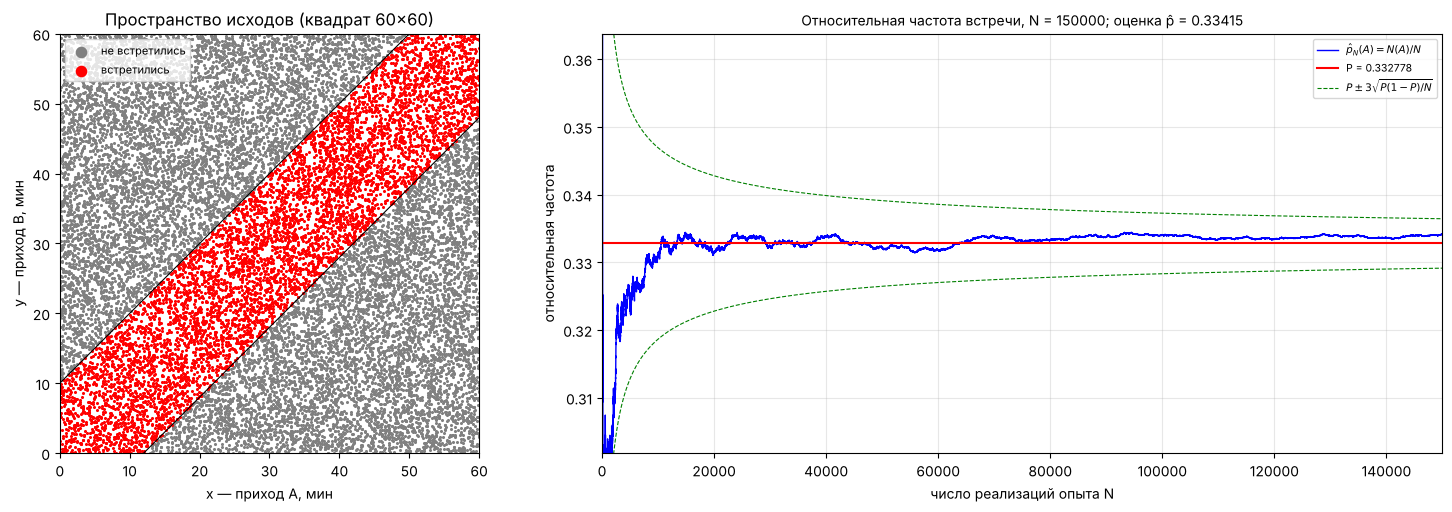

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={'width_ratios': [1, 1.7]})
m = 20_000                                                      # на диаграмме показываем первые 20 000 точек
axs[0].scatter(x[:m][~hit[:m]], y[:m][~hit[:m]], s=1.5, c='gray', label='не встретились')
axs[0].scatter(x[:m][hit[:m]], y[:m][hit[:m]], s=1.5, c='red', label='встретились')
tt = np.array([0, 60]); axs[0].plot(tt, tt + 10, 'k-', lw=0.8); axs[0].plot(tt, tt - 12, 'k-', lw=0.8)
axs[0].set_xlim(0, 60); axs[0].set_ylim(0, 60); axs[0].set_aspect('equal'); axs[0].set_xlabel('x — приход A, мин'); axs[0].set_ylabel('y — приход B, мин')
axs[0].legend(markerscale=6, loc='upper left', fontsize=8); axs[0].set_title('Пространство исходов (квадрат 60×60)')
plot_frequency(axs[1], hit, P_exact, f'Относительная частота встречи, N = {N}; оценка p̂ = {hit.mean():.5f}')
plt.tight_layout(); plt.savefig('task_4_6.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
$\mathbb P(A)=\dfrac{599}{1800}\approx0{,}332778$. Моделирование ($N=150\,000$) даёт оценку $\hat p(A)=N_A/N$ (см. вывод ячейки выше), близкую к точному значению; график относительной частоты стабилизируется около красной линии.